In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import h5py

In [7]:
results_dir = Path("num_results_loc/computed_manifolds")
poincare_dir = Path("num_results_loc/poincare_plots")

configs = list(range(11, 20)) + list(range(110, 139)) + [21, 22, 23]

manifolds = {}
parameters = {}
poincare_plots = {}

for config_id in configs:
    # Load manifolds
    path = results_dir / f"manifolds_{config_id}.npz"
    with np.load(path) as data:
        manifolds[config_id] = {
            key: data[key].copy()
            for key in data.files
        }

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)

    # Load Poincare trajectories
    path_poincare = poincare_dir / f"pplot_{config_id}.npz"
    with np.load(path_poincare) as data:
        poincare_plots[config_id] = data["hits"].copy()

In [3]:
def manifold_x_at_theta(manifold, theta=np.pi):
    """
    Find the first crossing of a manifold with theta,
    interpolating linearly between consecutive points.
    """

    points = np.asarray(manifold)
    x = points[:, 0]
    y = points[:, 1]

    # Find the first pair of consecutive points bracketing theta
    crossings = np.where((y[:-1] - theta) * (y[1:] - theta) <= 0)[0]

    if len(crossings) == 0:
        raise ValueError(f"No manifold segment crosses theta={theta:.4f}.")

    i = crossings[0]

    # Linear interpolation
    if np.isclose(y[i+1], y[i]):
        return x[i]

    x_interp = x[i] + (theta - y[i]) * (x[i+1] - x[i]) / (y[i+1] - y[i])

    return x_interp

In [4]:
temperature_dir = Path("num_results_loc/FaADE")

def plot_temperature_slope(config_id, t_f=0.01, k_values=(4.0, 6.0, 8.0, 10.0, 12.0),
                           nx=201, colors=("red", "orange", "green", "purple", "blue"), ax=None):

    params = parameters[config_id]
    data = manifolds[config_id]
    delta1, delta2 = params["delta1"], params["delta2"]
    iota = params["iota_prime"]

    # Island centers
    if config_id==13:
        man1 = data["stable2"]
        man4 = data["stable4"]
    else:
        man1 = data["stable1"]
        man4 = data["stable4"]
    x_right = manifold_x_at_theta(man1, theta=np.pi)
    x_left = manifold_x_at_theta(man4, theta=np.pi)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    else:
        fig = ax.figure

    # Mark island centers
    ax.axvline(x_right, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.axvline(x_left, color="black", linestyle="--", linewidth=1, alpha=0.7)

    mean_slopes = {}

    for exp_k, color in zip(k_values, colors):

        filename = (f"2I_k{float(exp_k)}_tf{t_f}_d{delta1}_{delta2}_res{nx}_"
                    f"m1_dT_iota{float(iota)}_Neumann.jld2")
        path = temperature_dir / filename

        if not path.exists():
            print(f"Temperature file not found: {filename}")
            continue

        with h5py.File(path, "r") as f:
            x_mid = np.asarray(f["x_mid"]).squeeze()
            u_mid = np.asarray(f["u_mid"]).squeeze()

        slope = np.gradient(u_mid, x_mid, edge_order=2)

        # Mean slope between island centers
        mask = (x_mid > x_left) & (x_mid < x_right)

        if not np.any(mask):
            raise ValueError(f"No grid points between island centers for configuration {config_id}.")

        mean_slope = np.mean(slope[mask])
        mean_slopes[exp_k] = mean_slope

        # Temperature gradient
        ax.plot(x_mid, slope, color=color, linewidth=2,
                label=rf"$\kappa_\perp/\kappa_\parallel = 10^{{-{int(exp_k)}}}$")

        # Mean slope between island centers
        ax.hlines(mean_slope, x_left, x_right, colors=color,
                  linestyles=":", linewidth=2)

    ax.set_xlim(0, 2)
    ax.set_xlabel("x")
    ax.set_ylabel(r"$dT/dx$")
    ax.hlines(y=0, colors="black", xmin=0, xmax=2, linestyles="--", linewidth=1, alpha=0.7)
    ax.set_title(
        rf"$\delta_1={params['delta1']},\ "
        rf"\delta_2={params['delta2']},\ "
        rf"\iota'={params['iota_prime']}$"
    )

    # Display mean slopes in a text box
    if mean_slopes:
        from matplotlib.offsetbox import AnchoredOffsetbox, VPacker, TextArea

        entries = [
            TextArea(rf"$k={int(k)}$: {value:.4f}",
                     textprops={"fontsize": 9})
            for k, value in mean_slopes.items()
        ]

        box = VPacker(children=entries, align="left", pad=0, sep=2)
        anchored = AnchoredOffsetbox(loc="upper right", child=box, frameon=True,
                                     bbox_to_anchor=(0.98, 0.98),
                                     bbox_transform=ax.transAxes, borderpad=0.3)
        ax.add_artist(anchored)

    return fig, ax

In [5]:
def plot_configurations_slopes(config_ids, ncols=3, figsize_per_subplot=(5, 4),
                               t_f=0.01, k_values=(4.0, 6.0, 8.0, 10.0, 12.0),
                               save_name=None, sharey=True):

    n = len(config_ids)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_subplot[0] * ncols, figsize_per_subplot[1] * nrows),
                             squeeze=False, sharex=True, sharey=sharey)

    for ax, config_id in zip(axes.flat, config_ids):
        plot_temperature_slope(config_id, t_f=t_f, k_values=k_values, ax=ax)
        ax.grid(alpha=0.2)

    # Hide unused subplots
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)

    # Shared legend
    handles, labels = axes.flat[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.01),
                   ncol=len(handles), title="Parallel transport",
                   fontsize=10, title_fontsize=11, frameon=True)

    fig.tight_layout(rect=[0, 0.09, 1, 1])

    if save_name is not None:
        save_dir = Path("Figures/comparisons")
        save_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_dir / f"{save_name}.png", dpi=300, bbox_inches="tight")

    return fig, axes

In [ ]:
temperature_dir = Path("num_results_loc/FaADE")

def compute_temperature_slopes(config_id, t_f=0.01, k_values=(8.0, 10.0, 12.0), nx=201):

    params = parameters[config_id]
    data = manifolds[config_id]
    delta1, delta2 = params["delta1"], params["delta2"]
    iota = params["iota_prime"]

    # Island centers
    if config_id==13:
        man1 = data["stable2"]
        man4 = data["stable4"]
    else:
        man1 = data["stable1"]
        man4 = data["stable4"]
    x_right = manifold_x_at_theta(man1, theta=np.pi)
    x_left = manifold_x_at_theta(man4, theta=np.pi)

    mean_slopes = {}

    for exp_k, color in zip(k_values, colors):

        filename = (f"2I_k{float(exp_k)}_tf{t_f}_d{delta1}_{delta2}_res{nx}_"
                    f"m1_dT_iota{float(iota)}_Neumann.jld2")
        path = temperature_dir / filename

        if not path.exists():
            print(f"Temperature file not found: {filename}")
            continue

        with h5py.File(path, "r") as f:
            x_mid = np.asarray(f["x_mid"]).squeeze()
            u_mid = np.asarray(f["u_mid"]).squeeze()

        slope = np.gradient(u_mid, x_mid, edge_order=2)

        # Mean slope between island centers
        mask = (x_mid > x_left) & (x_mid < x_right)

        if not np.any(mask):
            raise ValueError(f"No grid points between island centers for configuration {config_id}.")

        mean_slope = np.mean(slope[mask])
        mean_slopes[exp_k] = mean_slope

    return mean_slopes

In [ ]:
def plot_mean_slopes(config_ids, t_f=0.01, k_values=(8.0, 10.0, 12.0), colors=("red", "orange", "green", "purple", "blue")):
    fig, ax = plt.subplots(figsize=(8, 6))

    for config_id in config_ids:
        params = parameters[config_id]
        delta1, delta2 = params["delta1"], params["delta2"]
        mean_slopes = compute_temperature_slopes(config_id, t_f=t_f, k_values=k_values)
        for k in range(len(k_values)):
            ax.scatter(delta1, mean_slopes[k_values[k]], color=colors[k])
    return fig, ax

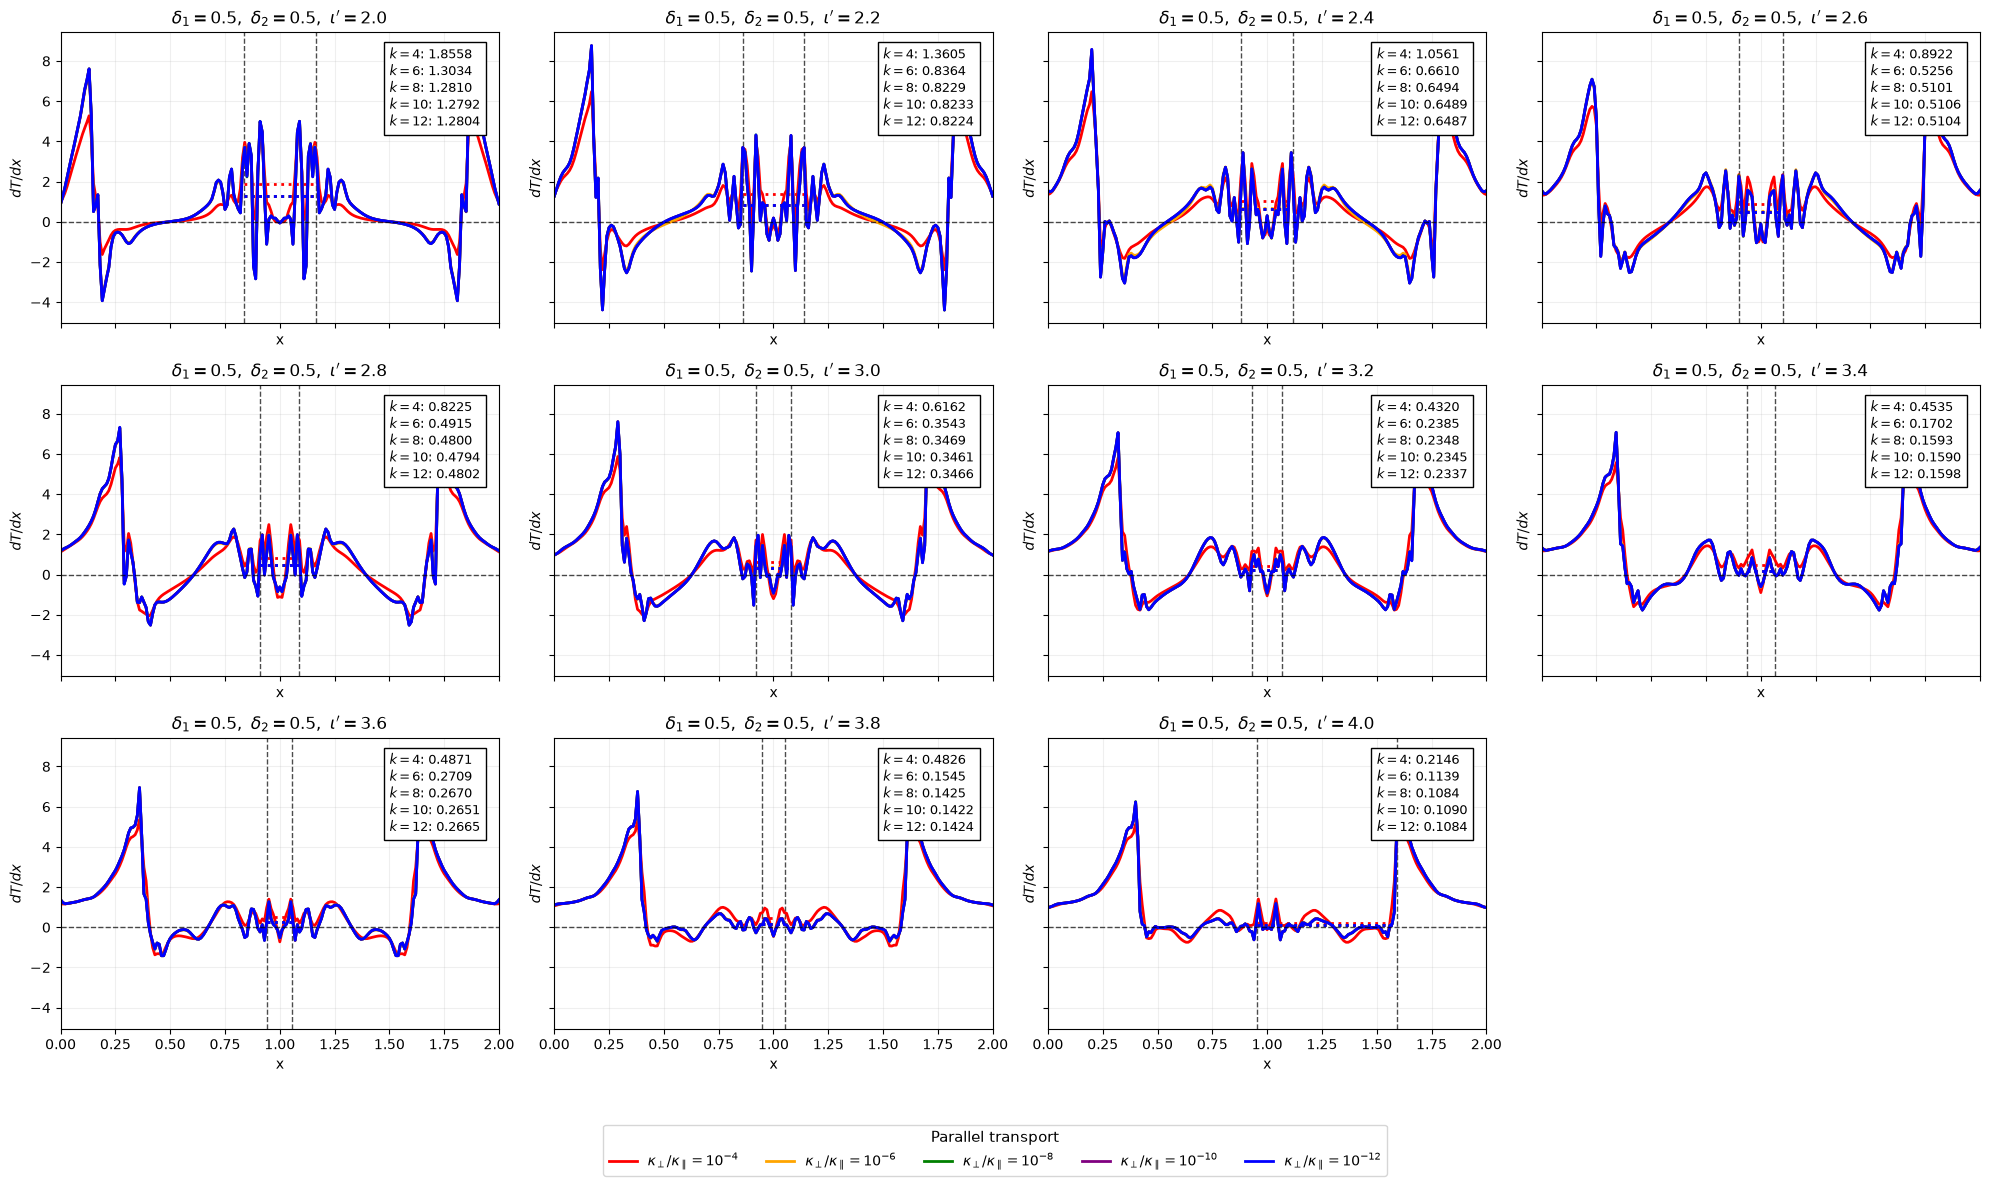

In [12]:
configs_1 = [12, 112, 111, 110, 19, 18, 17, 16, 15, 14, 13]
fig1, axes1 = plot_configurations_slopes(configs_1, ncols=4, save_name="slopes_delta_0.5")
plt.show()

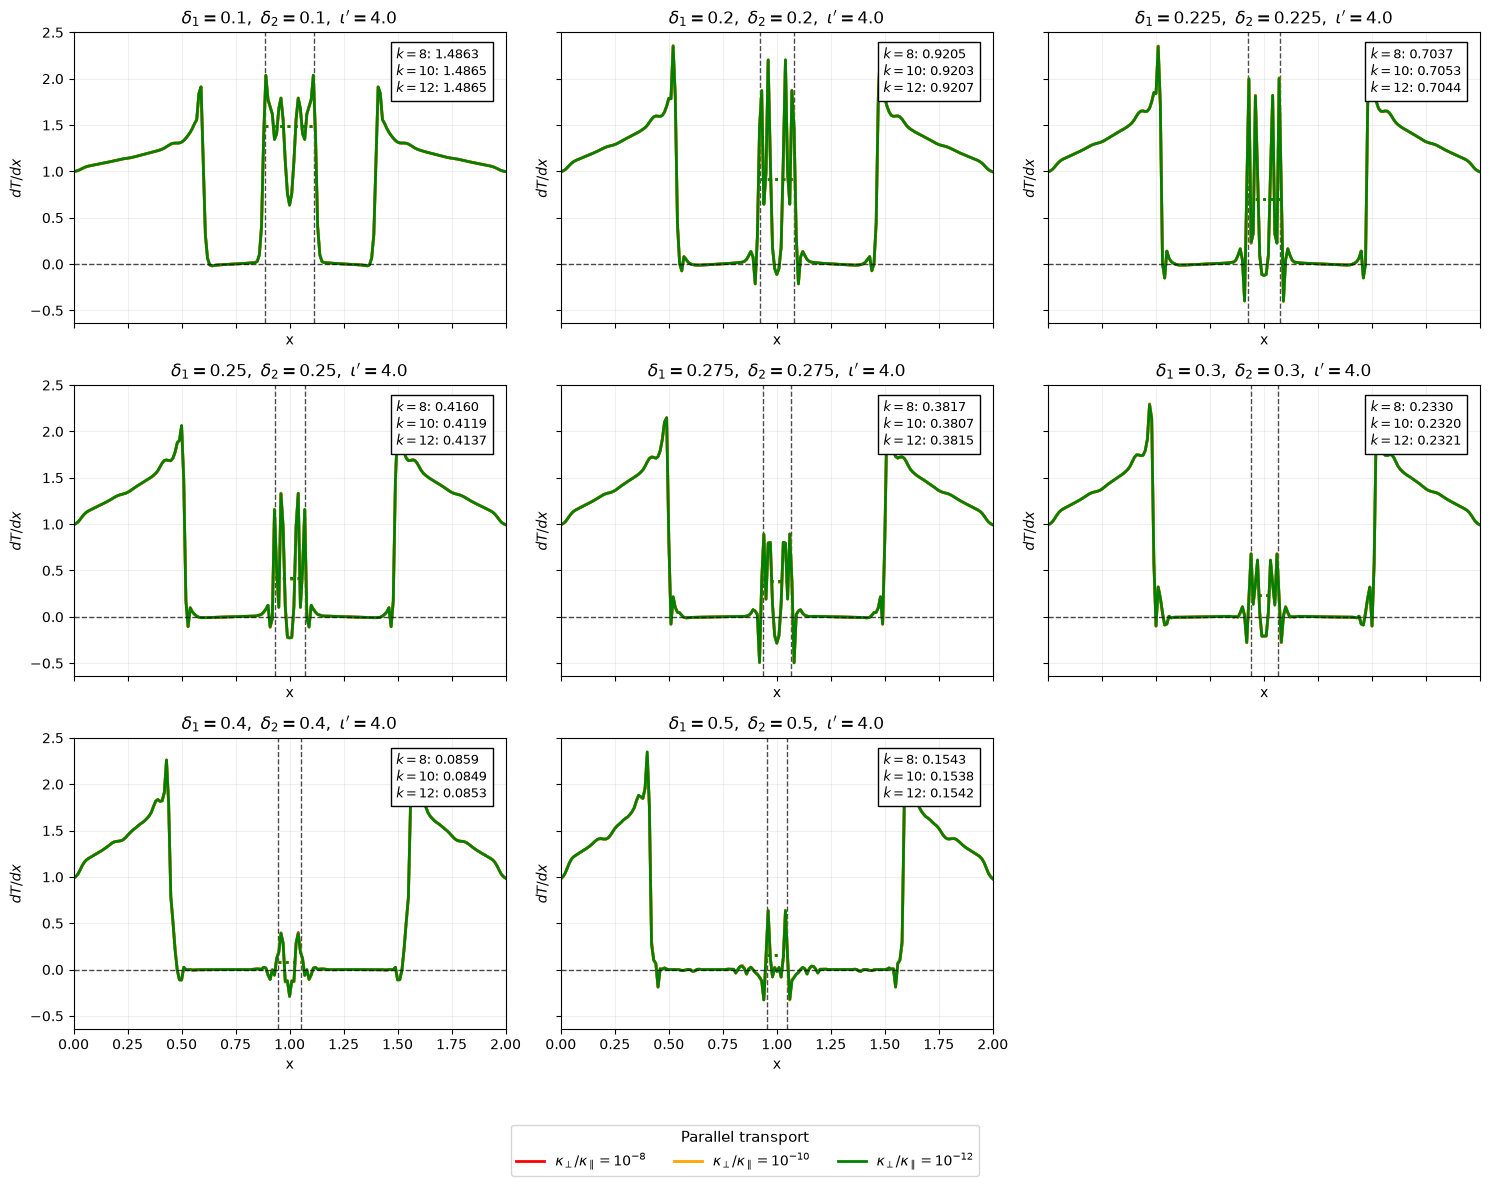

In [17]:
configs_2 = [114, 113, 129, 130, 131, 117, 116, 13]
t_f = 0.2
fig2, axes2 = plot_configurations_slopes(configs_2, t_f=t_f, ncols=3, save_name=f"slopes_tf{t_f}_iota4.0", k_values=(8.0, 10.0, 12.0))
plt.show()

(<Figure size 800x600 with 1 Axes>, <Axes: >)

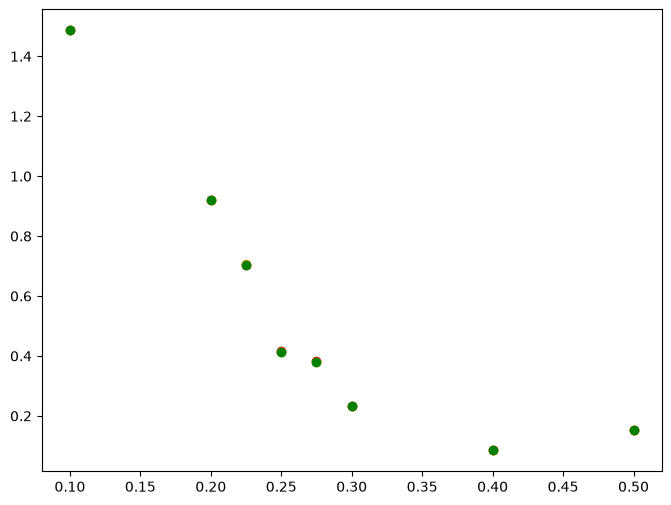

In [18]:
plot_mean_slopes(config_ids=configs_2, t_f=0.2)

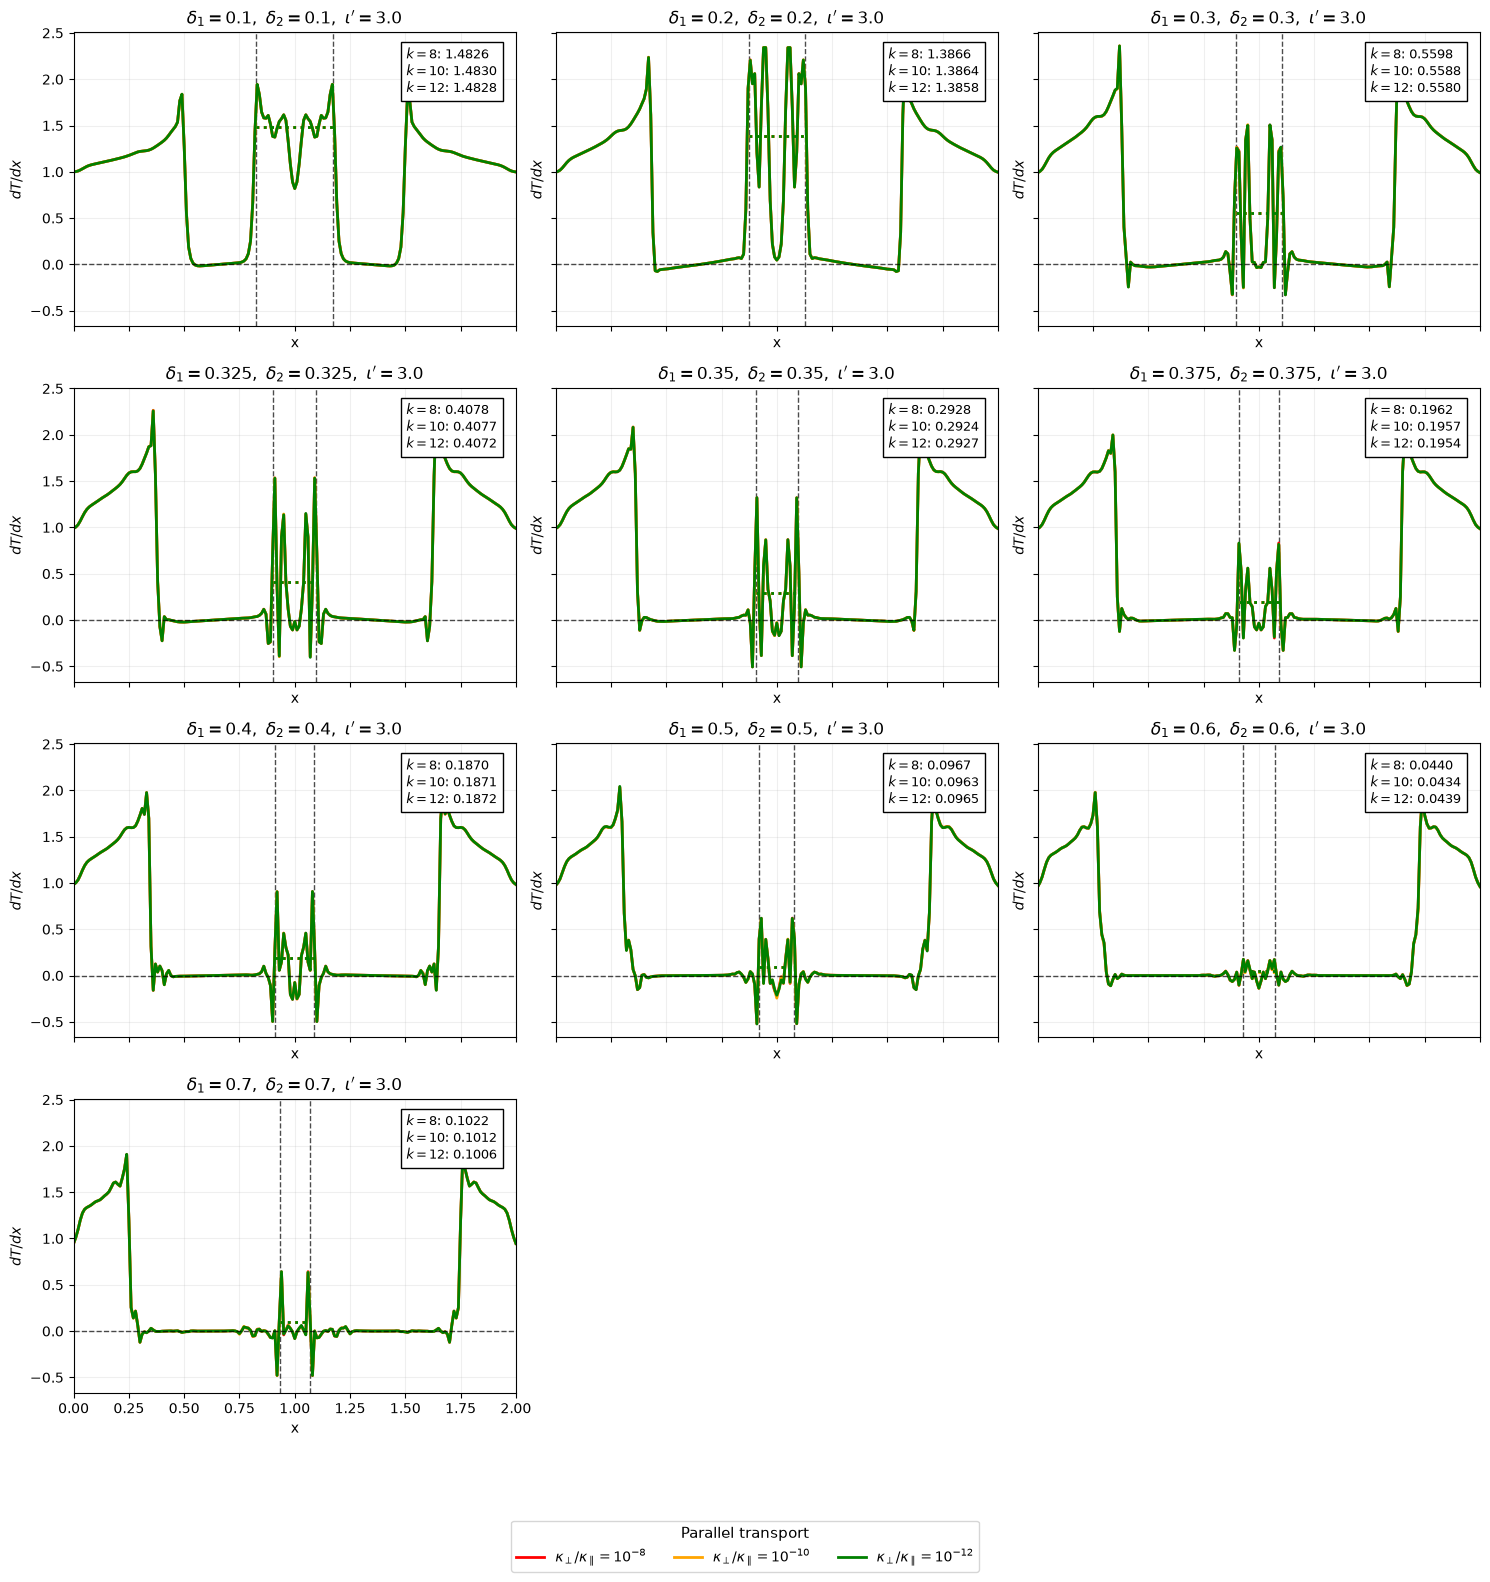

In [21]:
configs_3 = [119, 118, 122, 132, 133, 134, 123, 18, 120, 121] 
t_f = 0.2
fig3, axes3 = plot_configurations_slopes(configs_3, ncols=3, t_f=t_f, save_name=f"slopes_tf{t_f}_iota3.0", k_values=(8.0, 10.0, 12.0))
plt.show()

(<Figure size 800x600 with 1 Axes>, <Axes: >)

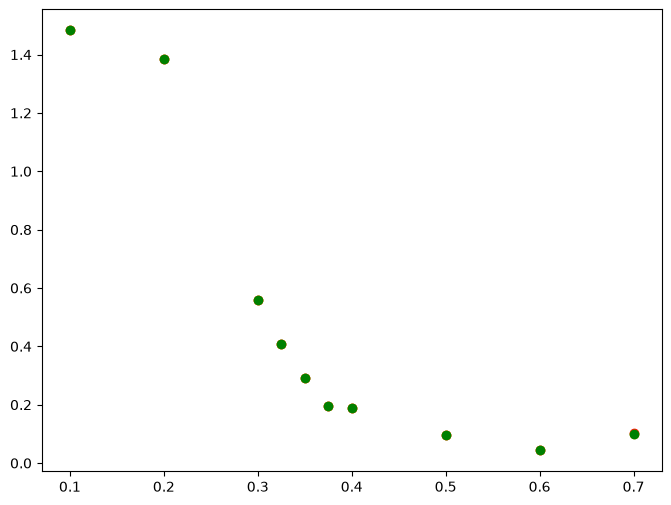

In [22]:
plot_mean_slopes(config_ids=configs_3, t_f=0.2)

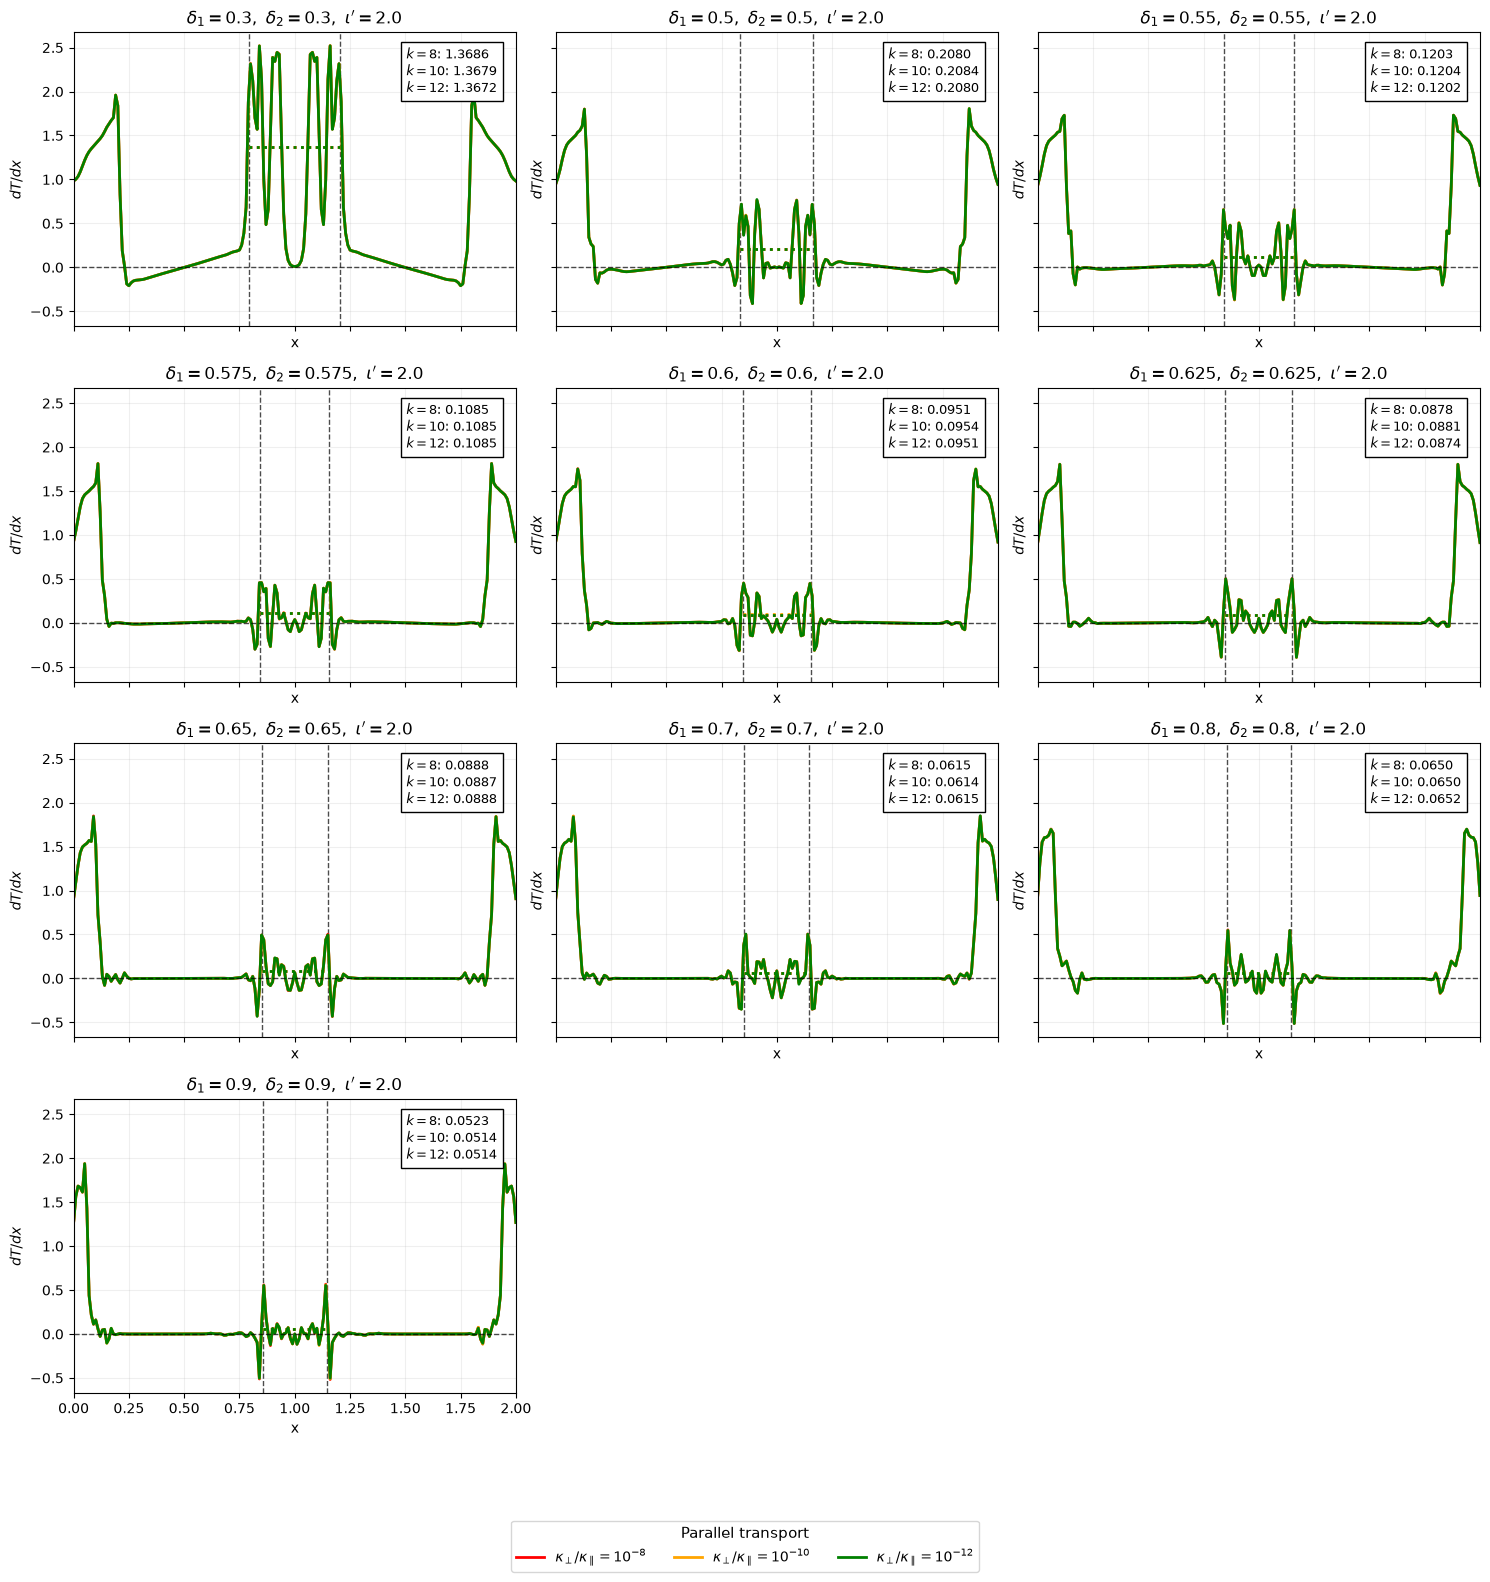

In [23]:
configs_4 = [124, 12, 135, 136, 125, 137, 138, 126, 127, 128] 
t_f = 0.2
fig3, axes3 = plot_configurations_slopes(configs_4, ncols=3, t_f=t_f, save_name=f"slopes_tf{t_f}_iota2.0", k_values=(8.0, 10.0, 12.0))
plt.show()

(<Figure size 800x600 with 1 Axes>, <Axes: >)

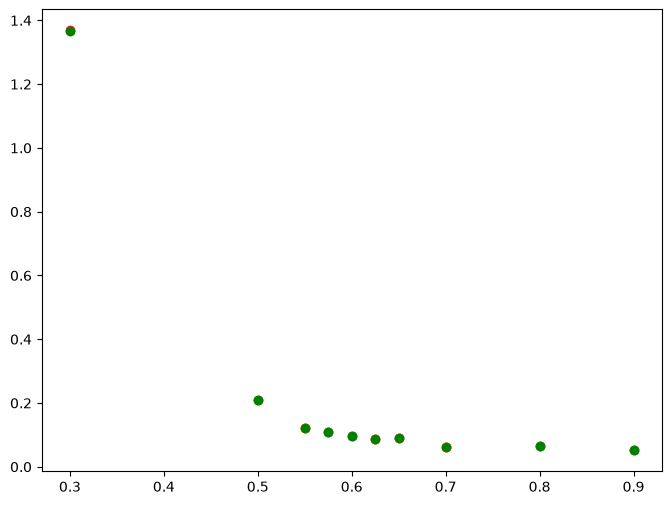

In [24]:
plot_mean_slopes(config_ids=configs_4, t_f=0.2)